In [1]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")

dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

In [2]:
from datasets import load_dataset

dataset = load_dataset("fancyzhx/ag_news")

dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

In [3]:
import pandas as pd

df = dataset["train"].to_pandas()

df.head()


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [4]:
df.shape

(120000, 2)

In [5]:
df.columns

Index(['text', 'label'], dtype='object')

In [6]:
df.isnull().sum()

text     0
label    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["label"].value_counts().sort_index()

label
0    30000
1    30000
2    30000
3    30000
Name: count, dtype: int64

In [9]:
df["text"].iloc[0]

"Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again."

In [10]:
df["text"].sample(5, random_state=42).tolist()

['BBC set for major shake-up, claims newspaper London - The British Broadcasting Corporation, the world #39;s biggest public broadcaster, is to cut almost a quarter of its 28 000-strong workforce, in the biggest shake-up in its 82-year history, The Times newspaper in London said on Monday.',
 'Marsh averts cash crunch Embattled insurance broker #39;s banks agree to waive clause that may have prevented access to credit. NEW YORK (Reuters) - Marsh  amp; McLennan Cos.',
 'Jeter, Yankees Look to Take Control (AP) AP - Derek Jeter turned a season that started with a terrible slump into one of the best in his accomplished 10-year career.',
 'Flying the Sun to Safety When the Genesis capsule comes back to Earth with its samples of the sun, helicopter pilots will be waiting for it, ready to snag it out of the sky.',
 'Stocks Seen Flat as Nortel and Oil Weigh  NEW YORK (Reuters) - U.S. stocks were set to open near  unchanged on Thursday after a warning from technology  bellwether Nortel Network

In [11]:
# Article length analysis

df["word_count"] = df["text"].str.split().str.len()

print("Article length statistics:")
print(df["word_count"].describe())

print("\nArticles with fewer than 5 words:")
print((df["word_count"] < 5).sum())

print("\nArticles with fewer than 10 words:")
print((df["word_count"] < 10).sum())

print("\nLongest article:")
print(df["word_count"].max())

Article length statistics:
count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64

Articles with fewer than 5 words:
0

Articles with fewer than 10 words:
7

Longest article:
177


In [12]:
# Save the original training dataset
df.to_csv("../data/ag_news_train_raw.csv", index=False)

print("Saved:", df.shape)

Saved: (120000, 3)


In [13]:
df[["text", "label"]].to_csv(
    "../data/ag_news_train_raw.csv",
    index=False
)

print("Saved:", df[["text", "label"]].shape)

Saved: (120000, 2)


In [14]:
#data cleaning


In [15]:
sample_text = df["text"].sample(10, random_state=42)

for i, text in enumerate(sample_text, 1):
    print(f"\n--- Article {i} ---")
    print(text)


--- Article 1 ---
BBC set for major shake-up, claims newspaper London - The British Broadcasting Corporation, the world #39;s biggest public broadcaster, is to cut almost a quarter of its 28 000-strong workforce, in the biggest shake-up in its 82-year history, The Times newspaper in London said on Monday.

--- Article 2 ---
Marsh averts cash crunch Embattled insurance broker #39;s banks agree to waive clause that may have prevented access to credit. NEW YORK (Reuters) - Marsh  amp; McLennan Cos.

--- Article 3 ---
Jeter, Yankees Look to Take Control (AP) AP - Derek Jeter turned a season that started with a terrible slump into one of the best in his accomplished 10-year career.

--- Article 4 ---
Flying the Sun to Safety When the Genesis capsule comes back to Earth with its samples of the sun, helicopter pilots will be waiting for it, ready to snag it out of the sky.

--- Article 5 ---
Stocks Seen Flat as Nortel and Oil Weigh  NEW YORK (Reuters) - U.S. stocks were set to open near  unc

In [16]:
import re
import nltk

from nltk.corpus import stopwords

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\utkar\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [17]:
stop_words = set(stopwords.words("english"))

print("Number of stopwords:", len(stop_words))

Number of stopwords: 198


In [18]:
def preprocess_text(text):
    # 1. Convert to lowercase
    text = text.lower()

    # 2. Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # 3. Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # 4. Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # 5. Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [19]:
sample = df["text"].sample(5, random_state=42)

for i, text in enumerate(sample, 1):
    print(f"\n{'='*80}")
    print(f"ARTICLE {i}")
    print(f"{'='*80}")

    print("\nRAW:")
    print(text)

    print("\nCLEANED:")
    print(preprocess_text(text))


ARTICLE 1

RAW:
BBC set for major shake-up, claims newspaper London - The British Broadcasting Corporation, the world #39;s biggest public broadcaster, is to cut almost a quarter of its 28 000-strong workforce, in the biggest shake-up in its 82-year history, The Times newspaper in London said on Monday.

CLEANED:
bbc set major shake claims newspaper london british broadcasting corporation world biggest public broadcaster cut almost quarter strong workforce biggest shake year history times newspaper london said monday

ARTICLE 2

RAW:
Marsh averts cash crunch Embattled insurance broker #39;s banks agree to waive clause that may have prevented access to credit. NEW YORK (Reuters) - Marsh  amp; McLennan Cos.

CLEANED:
marsh averts cash crunch embattled insurance broker banks agree waive clause may prevented access credit new york reuters marsh amp mclennan cos

ARTICLE 3

RAW:
Jeter, Yankees Look to Take Control (AP) AP - Derek Jeter turned a season that started with a terrible slump int

In [20]:
df["clean_text"] = df["text"].apply(preprocess_text)

In [21]:
df[["text", "clean_text"]].head()

,text,clean_text
0,Wall St. Bears Claw Back Into the Black (Reute...,wall st bears claw back black reuters reuters ...
1,Carlyle Looks Toward Commercial Aerospace (Reu...,carlyle looks toward commercial aerospace reut...
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,oil economy cloud stocks outlook reuters reute...
3,Iraq Halts Oil Exports from Main Southern Pipe...,iraq halts oil exports main southern pipeline ...
4,"Oil prices soar to all-time record, posing new...",oil prices soar time record posing new menace ...


In [22]:
print("Original articles:", len(df))
print("Cleaned articles:", df["clean_text"].notna().sum())

print("\nEmpty cleaned articles:")
print((df["clean_text"].str.len() == 0).sum())

print("\nCleaned text statistics:")
print(df["clean_text"].str.split().str.len().describe())

Original articles: 120000
Cleaned articles: 120000

Empty cleaned articles:
0

Cleaned text statistics:
count    120000.000000
mean         25.860642
std           7.778657
min           6.000000
25%          21.000000
50%          25.000000
75%          29.000000
max         131.000000
Name: clean_text, dtype: float64


In [23]:
#import tf-idf
from sklearn.feature_extraction.text import TfidfVectorizer

In [24]:
#create the vectorized
tfidf = TfidfVectorizer(
    max_features=30000,
    min_df=5,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True
)

In [25]:
#Step 12.3 Fit TF-IDF
X_tfidf = tfidf.fit_transform(df["clean_text"])

In [26]:
print("TF-IDF shape:", X_tfidf.shape)
print("Number of non-zero values:", X_tfidf.nnz)

TF-IDF shape: (120000, 30000)
Number of non-zero values: 3187046


In [27]:
#Step 12.4 Check sparsity
total_values = X_tfidf.shape[0] * X_tfidf.shape[1]
sparsity = 1 - (X_tfidf.nnz / total_values)

print(f"Sparsity: {sparsity:.4%}")

Sparsity: 99.9115%


In [28]:
#Step 12.5 Look at the vocabulary
feature_names = tfidf.get_feature_names_out()

print("Number of features:", len(feature_names))
print("\nFirst 50 features:")
print(feature_names[:50])

Number of features: 30000

First 50 features:
['aa' 'aapl' 'aapl lt' 'aaron' 'aaron peirsol' 'aaron rodgers' 'ab'
 'ababa' 'abandon' 'abandoned' 'abandoning' 'abandons' 'abbas' 'abbey'
 'abbey national' 'abbott' 'abc' 'abdication' 'abducted' 'abduction'
 'abductors' 'abdul' 'abdullah' 'aberdeen' 'abide' 'abidjan'
 'abidjan ivory' 'abidjan reuters' 'ability' 'abimael' 'abimael guzman'
 'ablaze' 'able' 'able get' 'able make' 'able use' 'abn' 'abn amro'
 'aboard' 'aboard international' 'aboriginal' 'abortion' 'abound'
 'abraham' 'abramovich' 'abroad' 'abrupt' 'abruptly' 'absa' 'absence']


In [29]:
print("\nSample TF-IDF vector:")
print(X_tfidf[0])


Sample TF-IDF vector:
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 19 stored elements and shape (1, 30000)>
  Coords	Values
  (0, 28698)	0.2929769872257582
  (0, 24933)	0.1700294102498364
  (0, 2291)	0.21974927483646028
  (0, 4441)	0.30547421927012613
  (0, 1911)	0.13694231248681127
  (0, 2690)	0.19664450815948495
  (0, 21845)	0.1701090662865938
  (0, 23913)	0.18592941426735643
  (0, 23398)	0.2790763890637763
  (0, 25428)	0.16822374547613922
  (0, 7368)	0.28658986847367013
  (0, 2044)	0.23443660841154493
  (0, 27758)	0.26059930306260826
  (0, 23343)	0.24269928461582474
  (0, 10618)	0.192235314055459
  (0, 28699)	0.2654703138517981
  (0, 4442)	0.3091437866345767
  (0, 21957)	0.13542334598948885
  (0, 28700)	0.1768920549230795


In [31]:
# Step 13 — TruncatedSVD
from sklearn.decomposition import TruncatedSVD

In [32]:
# 13.2 Create the SVD model
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

In [33]:
# 13.3 Transform our TF-IDF matrix
X_svd = svd.fit_transform(X_tfidf)

In [34]:
print("Original TF-IDF shape:", X_tfidf.shape)
print("SVD shape:", X_svd.shape)

Original TF-IDF shape: (120000, 30000)
SVD shape: (120000, 100)


In [35]:
explained_variance = svd.explained_variance_ratio_.sum()

print(f"Explained variance with 100 components: {explained_variance:.4%}")

Explained variance with 100 components: 9.4435%


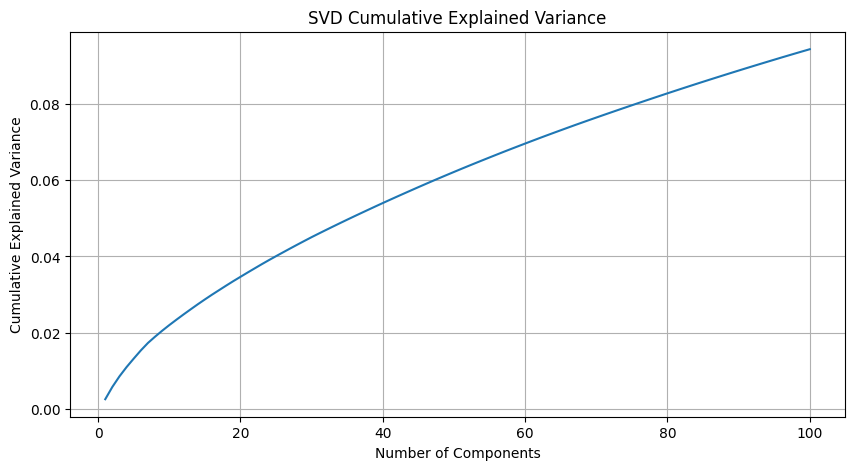

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, 101),
    svd.explained_variance_ratio_.cumsum()
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("SVD Cumulative Explained Variance")
plt.grid(True)
plt.show()

Phase 7   Dimensionality reduction with TruncatedSVD

Phase 8

In [37]:
# 8.1 Import K-Means
from sklearn.cluster import KMeans

In [38]:
# 8.2 First baseline: K = 4
kmeans_4 = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

In [39]:
cluster_labels_4 = kmeans_4.fit_predict(X_svd)

In [40]:
# 8.3 Check the cluster distribution
import numpy as np

unique, counts = np.unique(cluster_labels_4, return_counts=True)

for cluster, count in zip(unique, counts):
    print(f"Cluster {cluster}: {count:,} articles")

Cluster 0: 1,520 articles
Cluster 1: 3,125 articles
Cluster 2: 3,638 articles
Cluster 3: 111,717 articles


In [41]:
# 8.4 Add cluster assignments to our dataframe
df["cluster"] = cluster_labels_4


df[["text", "label", "cluster"]].head(10)


,text,label,cluster
0,Wall St. Bears Claw Back Into the Black (Reute...,2,3
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,3
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,1
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,1
4,"Oil prices soar to all-time record, posing new...",2,1
5,"Stocks End Up, But Near Year Lows (Reuters) Re...",2,1
6,Money Funds Fell in Latest Week (AP) AP - Asse...,2,3
7,Fed minutes show dissent over inflation (USATO...,2,3
8,Safety Net (Forbes.com) Forbes.com - After ear...,2,3
9,Wall St. Bears Claw Back Into the Black NEW Y...,2,3


In [42]:
# 8.6 Find representative articles
distances = kmeans_4.transform(X_svd)

for cluster_id in range(4):
    cluster_distances = distances[:, cluster_id]

    closest_indices = np.argsort(cluster_distances)[:5]

    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id}")
    print(f"{'='*80}")

    for idx in closest_indices:
        print("\n", df.iloc[idx]["text"])


CLUSTER 0

 Tyson Foods Reports Lower Earnings  CHICAGO (Reuters) - Tyson Foods Inc. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=TSN.N target=/stocks/quickinfo/fullquote"&gt;TSN.N&lt;/A&gt;, the nation's  largest meat producer, on Monday reported a sharp drop in  quarterly earnings due in part to poor results in its beef  segment.

 Tyson Foods Posts Lower Earnings  CHICAGO (Reuters) - Tyson Foods Inc. &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=TSN.N target=/stocks/quickinfo/fullquote"&gt;TSN.N&lt;/A&gt;, the largest  U.S. meat producer, on Monday said quarterly earnings dropped  by more than 50 percent in part to poor results in its beef  segment.

 Clear Channel Radio Ad Revenue Slips  NEW YORK (Reuters) - Clear Channel Communications Inc.  &lt;A HREF="http://www.investor.reuters.com/FullQuote.aspx?ticker=CCU.N target=/stocks/quickinfo/fullquote"&gt;CCU.N&lt;/A&gt;, the largest U.S. radio station chain, on Friday posted  higher operating 

Phase 5 — Evaluate your clusters

In [43]:
# Step 1 — Check cluster sizes
import pandas as pd

cluster_counts = df["cluster"].value_counts().sort_index()

print("Number of articles in each cluster:")
print(cluster_counts)

Number of articles in each cluster:
cluster
0      1520
1      3125
2      3638
3    111717
Name: count, dtype: int64


In [44]:
# Step 2 — Calculate Silhouette Score
from sklearn.metrics import silhouette_score

sample_size = min(10000, len(df))

sample_indices = df.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_tfidf[sample_indices]
labels_sample = df.loc[sample_indices, "cluster"]

sil_score = silhouette_score(
    X_sample,
    labels_sample
)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.0020331791529272507


In [45]:
# Step 3 — Calculate Davies-Bouldin Index
from sklearn.metrics import davies_bouldin_score

db_score = davies_bouldin_score(
    X_sample.toarray(),
    labels_sample
)

print("Davies-Bouldin Index:", db_score)

Davies-Bouldin Index: 5.871851112217212


In [47]:
# Step 4 — Calculate Calinski-Harabasz Score
from sklearn.metrics import calinski_harabasz_score

ch_score = calinski_harabasz_score(
    X_sample.toarray(),
    labels_sample
)

print("Calinski-Harabasz Score:", ch_score)

Calinski-Harabasz Score: 30.653670792354756


Yes — don't move to the next phase yet. The scores show that the current clustering is genuinely bad:

Cluster 0 → 1,520
Cluster 1 → 3,125
Cluster 2 → 3,638
Cluster 3 → 111,717
Silhouette → 0.0020 ❌
Davies-Bouldin → 5.87 ❌
Calinski-Harabasz → 30.65 ❌

The biggest problem is that K-Means has collapsed almost all 120,000 articles into one cluster.

Why this happened

In [49]:
from sklearn.decomposition import TruncatedSVD

# Reduce TF-IDF dimensionality
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_svd = svd.fit_transform(X_tfidf)

print("Original TF-IDF shape:", X_tfidf.shape)
print("SVD shape:", X_svd.shape)
print("Explained variance:", svd.explained_variance_ratio_.sum())

Original TF-IDF shape: (120000, 30000)
SVD shape: (120000, 100)
Explained variance: 0.0944348629074251


In [51]:
from sklearn.preprocessing import Normalizer

normalizer = Normalizer(copy=False)

X_reduced = normalizer.fit_transform(X_svd)

print("Reduced matrix shape:", X_reduced.shape)

Reduced matrix shape: (120000, 100)


In [52]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=42
)

clusters = kmeans.fit_predict(X_reduced)

df["cluster_new"] = clusters

print("Clustering completed.")

Clustering completed.


In [53]:
cluster_counts = df["cluster_new"].value_counts().sort_index()

print("New cluster sizes:")
print(cluster_counts)

print("\nCluster percentages:")
print((cluster_counts / len(df) * 100).round(2))

New cluster sizes:
cluster_new
0     7750
1    29100
2    28561
3    54589
Name: count, dtype: int64

Cluster percentages:
cluster_new
0     6.46
1    24.25
2    23.80
3    45.49
Name: count, dtype: float64


In [54]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Sample for Silhouette because 120k samples is expensive
sample_size = min(10000, len(df))

sample_indices = df.sample(
    n=sample_size,
    random_state=42
).index

X_sample = X_reduced[sample_indices]
labels_sample = df.loc[sample_indices, "cluster_new"]

sil_score = silhouette_score(
    X_sample,
    labels_sample
)

db_score = davies_bouldin_score(
    X_sample,
    labels_sample
)

ch_score = calinski_harabasz_score(
    X_sample,
    labels_sample
)

print("Silhouette Score:", sil_score)
print("Davies-Bouldin Index:", db_score)
print("Calinski-Harabasz Score:", ch_score)

Silhouette Score: 0.03568359961477956
Davies-Bouldin Index: 4.954113511633421
Calinski-Harabasz Score: 220.23561603544044


In [55]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [3, 4, 5, 6, 7, 8]

results = []

# Use the same 10,000 samples for fair comparison
sample_indices = df.sample(
    n=min(10000, len(df)),
    random_state=42
).index

X_eval = X_reduced[sample_indices]

for k in k_values:
    print(f"Testing K = {k}...")

    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels = km.fit_predict(X_reduced)

    score = silhouette_score(
        X_eval,
        labels[sample_indices]
    )

    results.append({
        "k": k,
        "silhouette": score,
        "inertia": km.inertia_
    })

results_df = pd.DataFrame(results)

print("\nResults:")
print(results_df)

Testing K = 3...
Testing K = 4...
Testing K = 5...
Testing K = 6...
Testing K = 7...
Testing K = 8...

Results:
   k  silhouette        inertia
0  3    0.028600  107398.177015
1  4    0.035559  104916.809279
2  5    0.040067  103245.513059
3  6    0.048484  101430.577147
4  7    0.055623   99888.705144
5  8    0.056829   98840.726265


In [56]:
results_df.sort_values("silhouette", ascending=False)

,k,silhouette,inertia
5,8,0.056829,98840.726265
4,7,0.055623,99888.705144
3,6,0.048484,101430.577147
2,5,0.040067,103245.513059
1,4,0.035559,104916.809279
0,3,0.028600,107398.177015


In [57]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values_extended = [8, 9, 10, 11, 12]

extended_results = []

sample_indices = df.sample(
    n=min(10000, len(df)),
    random_state=42
).index

X_eval = X_reduced[sample_indices]

for k in k_values_extended:

    print(f"Testing K = {k}...")

    km = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=42
    )

    labels = km.fit_predict(X_reduced)

    score = silhouette_score(
        X_eval,
        labels[sample_indices]
    )

    extended_results.append({
        "k": k,
        "silhouette": score,
        "inertia": km.inertia_
    })

extended_results_df = pd.DataFrame(extended_results)

print("\nExtended Results:")
print(extended_results_df)

Testing K = 8...
Testing K = 9...
Testing K = 10...
Testing K = 11...
Testing K = 12...

Extended Results:
    k  silhouette       inertia
0   8    0.056829  98840.726265
1   9    0.057886  97757.582720
2  10    0.064632  96277.249381
3  11    0.063937  95365.461639
4  12    0.067100  94247.803196


In [58]:
extended_results_df.sort_values(
    "silhouette",
    ascending=False
)

,k,silhouette,inertia
4,12,0.067100,94247.803196
2,10,0.064632,96277.249381
3,11,0.063937,95365.461639
1,9,0.057886,97757.582720
0,8,0.056829,98840.726265


In [59]:
from sklearn.cluster import KMeans

final_k = 12

final_kmeans = KMeans(
    n_clusters=final_k,
    init="k-means++",
    n_init=20,
    max_iter=300,
    random_state=42
)

df["cluster"] = final_kmeans.fit_predict(X_reduced)

print("Final clustering completed.")
print("\nCluster sizes:")
print(df["cluster"].value_counts().sort_index())

Final clustering completed.

Cluster sizes:
cluster
0      7454
1      7735
2      5415
3     15478
4      4112
5      5172
6      3463
7      2497
8     20588
9      6984
10    15473
11    25629
Name: count, dtype: int64


In [60]:
cluster_counts = df["cluster"].value_counts().sort_index()

print("Cluster percentages:")
print((cluster_counts / len(df) * 100).round(2))

Cluster percentages:
cluster
0      6.21
1      6.45
2      4.51
3     12.90
4      3.43
5      4.31
6      2.89
7      2.08
8     17.16
9      5.82
10    12.89
11    21.36
Name: count, dtype: float64


In [61]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

sample_indices = df.sample(
    n=min(10000, len(df)),
    random_state=42
).index

X_sample = X_reduced[sample_indices]
labels_sample = df.loc[sample_indices, "cluster"]

sil_score = silhouette_score(
    X_sample,
    labels_sample
)

db_score = davies_bouldin_score(
    X_sample,
    labels_sample
)

ch_score = calinski_harabasz_score(
    X_sample,
    labels_sample
)

print("FINAL K =", final_k)
print("Silhouette Score:", sil_score)
print("Davies-Bouldin Index:", db_score)
print("Calinski-Harabasz Score:", ch_score)

FINAL K = 12
Silhouette Score: 0.06710014635963958
Davies-Bouldin Index: 3.7157305935574185
Calinski-Harabasz Score: 172.8871503171302


Phase 5
│
├── Cluster size analysis       ✅
├── Initial evaluation          ✅
├── SVD improvement             ✅
├── K = 3–8 experiment         ✅
├── K = 8–12 experiment        ✅
└── Final K selection           → K = 12

Next step: Phase 5.1 — Improve the feature space

In [62]:
# 1. Add a new cell after your TF-IDF cell

from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

# Reduce TF-IDF dimensions
svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_svd = svd.fit_transform(X_tfidf)

print("SVD shape:", X_svd.shape)
print("Explained variance:", svd.explained_variance_ratio_.sum())

SVD shape: (120000, 100)
Explained variance: 0.0944348629074251


In [63]:
# 2. Normalize the SVD representation
normalizer = Normalizer(copy=False)

X_svd_norm = normalizer.fit_transform(X_svd)

print("Normalized shape:", X_svd_norm.shape)

Normalized shape: (120000, 100)


In [64]:
# 3. Run K-Means again with K = 12
from sklearn.cluster import KMeans

kmeans_svd = KMeans(
    n_clusters=12,
    random_state=42,
    n_init=10,
    max_iter=300
)

labels_svd = kmeans_svd.fit_predict(X_svd_norm)

print("Clustering completed.")

Clustering completed.


In [65]:
# Save the new cluster labels
df["cluster_svd"] = labels_svd

print(df["cluster_svd"].value_counts().sort_index())

cluster_svd
0      7454
1      7735
2      5415
3     15478
4      4112
5      5172
6      3463
7      2497
8     20588
9      6984
10    15473
11    25629
Name: count, dtype: int64


In [66]:
# Recalculate the three scores
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

sample_size = min(10000, len(df))

sample_indices = df.sample(
    n=sample_size,
    random_state=42
).index

X_eval = X_svd_norm[sample_indices]
labels_eval = df.loc[sample_indices, "cluster_svd"]

sil_score_svd = silhouette_score(
    X_eval,
    labels_eval
)

db_score_svd = davies_bouldin_score(
    X_eval,
    labels_eval
)

ch_score_svd = calinski_harabasz_score(
    X_eval,
    labels_eval
)

print("K = 12")
print("Silhouette Score:", sil_score_svd)
print("Davies-Bouldin Index:", db_score_svd)
print("Calinski-Harabasz Score:", ch_score_svd)

K = 12
Silhouette Score: 0.06710014635963173
Davies-Bouldin Index: 3.7157305935574185
Calinski-Harabasz Score: 172.88715031713016


In [67]:
# Compare old vs new
print("\n========== COMPARISON ==========")

print("OLD TF-IDF")
print("Silhouette:", 0.06710014635963958)
print("Davies-Bouldin:", 3.7157305935574185)
print("Calinski-Harabasz:", 172.8871503171302)

print("\nNEW TF-IDF + SVD")
print("Silhouette:", sil_score_svd)
print("Davies-Bouldin:", db_score_svd)
print("Calinski-Harabasz:", ch_score_svd)


========== COMPARISON ==========
OLD TF-IDF
Silhouette: 0.06710014635963958
Davies-Bouldin: 3.7157305935574185
Calinski-Harabasz: 172.8871503171302

NEW TF-IDF + SVD
Silhouette: 0.06710014635963173
Davies-Bouldin: 3.7157305935574185
Calinski-Harabasz: 172.88715031713016


🚀 Next: Phase 6 — Analyze & Interpret the Clusters

In [69]:
# ============================================================
# Phase 6 — Cluster Interpretation
# Step 6.1 — Find Top Terms in Each Cluster
# ============================================================

import numpy as np

# Get the feature names from TF-IDF
feature_names = tfidf.get_feature_names_out()

# Get cluster centers
cluster_centers = kmeans.cluster_centers_

print("Top terms for each cluster:\n")

for cluster_id in range(final_k):

    # Get indices of the highest-weighted terms
    top_indices = final_kmeans.cluster_centers_[cluster_id].argsort()[-15:][::-1]

    # Convert indices to words
    top_terms = [feature_names[i] for i in top_indices]

    print(f"\nCluster {cluster_id}")
    print("-" * 50)
    print(", ".join(top_terms))

Top terms for each cluster:


Cluster 0
--------------------------------------------------
aaron, ab, aa, aapl lt, aaron rodgers, abandons, abductors, abbey national, aberdeen, abc, abuja nigeria, abrupt, abimael, abu, absa

Cluster 1
--------------------------------------------------
aa, abandoning, aapl lt, abbas, abc, ababa, abdul, abdullah, abn, abide, abn amro, aberdeen, abducted, abidjan ivory, abu ghraib

Cluster 2
--------------------------------------------------
aa, abbey national, abbey, abc, abandoned, abductors, abbott, abimael, abraham, ability, abramovich, able get, abrupt, abbas, aboard

Cluster 3
--------------------------------------------------
aaron peirsol, aa, ababa, ab, abbas, abdullah, abdication, aberdeen, abidjan ivory, abimael guzman, abductors, abuja, abn, able use, absorb

Cluster 4
--------------------------------------------------
abbey national, abandons, abandon, aa, abducted, abandoning, abbott, ababa, abc, abductors, aapl lt, aaron peirsol, ability, a

In [70]:
# ============================================================
# Step 6.2 — Representative Articles
# ============================================================

for cluster_id in range(final_k):

    cluster_data = df[df["cluster"] == cluster_id]

    print("\n" + "=" * 70)
    print(f"CLUSTER {cluster_id} — {len(cluster_data)} articles")
    print("=" * 70)

    # Show first 5 articles
    for i, text in enumerate(cluster_data["clean_text"].head(5), 1):
        print(f"\nArticle {i}:")
        print(text[:500])


CLUSTER 0 — 7454 articles

Article 1:
money funds fell latest week ap ap assets nation retail money market mutual funds fell billion latest week trillion investment company institute said thursday

Article 2:
hacker cracks apple streaming technology ap ap norwegian hacker famed developing dvd encryption cracking software apparently struck time breaking locks apple computer inc wireless music streaming technology

Article 3:
charley force took experts surprise ap ap hurricane charley mph force took forecasters surprise showed shaky science still predict storm intensity even latest satellite radar technology

Article 4:
science politics collide election year ap ap scientists including nobel prize winners signed statement opposing bush administration use scientific advice election year seeing new development uneasy relationship science politics

Article 5:
building dedicated columbia astronauts ap ap former dormitory converted classrooms pensacola naval air station dedicated friday two c

In [71]:
import numpy as np

# Get TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

# Get cluster centers from the FINAL K-Means model
cluster_centers = final_kmeans.cluster_centers_

print("TOP TERMS FOR EACH CLUSTER")
print("=" * 80)

for cluster_id in range(final_k):
    
    # Get indices of highest-weighted terms
    top_indices = cluster_centers[cluster_id].argsort()[-15:][::-1]
    
    # Convert indices to actual words
    top_terms = [feature_names[i] for i in top_indices]
    
    print(f"\nCluster {cluster_id}")
    print("-" * 80)
    print(", ".join(top_terms))

TOP TERMS FOR EACH CLUSTER

Cluster 0
--------------------------------------------------------------------------------
aaron, ab, aa, aapl lt, aaron rodgers, abandons, abductors, abbey national, aberdeen, abc, abuja nigeria, abrupt, abimael, abu, absa

Cluster 1
--------------------------------------------------------------------------------
aa, abandoning, aapl lt, abbas, abc, ababa, abdul, abdullah, abn, abide, abn amro, aberdeen, abducted, abidjan ivory, abu ghraib

Cluster 2
--------------------------------------------------------------------------------
aa, abbey national, abbey, abc, abandoned, abductors, abbott, abimael, abraham, ability, abramovich, able get, abrupt, abbas, aboard

Cluster 3
--------------------------------------------------------------------------------
aaron peirsol, aa, ababa, ab, abbas, abdullah, abdication, aberdeen, abidjan ivory, abimael guzman, abductors, abuja, abn, able use, absorb

Cluster 4
-----------------------------------------------------------

NEXT: Phase 6 — Cluster Interpretation & Topic Labeling

In [72]:
# Phase 6 — Cluster Interpretation
# Step 1: Show representative articles from each cluster

for cluster_id in range(final_k):
    
    print("\n" + "=" * 80)
    print(f"CLUSTER {cluster_id}")
    print("=" * 80)

    cluster_data = df[df["cluster"] == cluster_id]

    # Show 5 representative/random articles
    samples = cluster_data.sample(
        min(5, len(cluster_data)),
        random_state=42
    )

    for i, text in enumerate(samples["text"], 1):
        print(f"\nArticle {i}:")
        print(text[:1000])


CLUSTER 0

Article 1:
GIs Find Belongings of Once-Missing Marine (AP) AP - U.S. troops have recovered personal effects of a U.S. Marine who was once feared beheaded by Iraqi insurgents after disappearing from his unit, U.S. officials said.

Article 2:
Unilever Issues Profit Warning (AP) AP - Unilever PLC, the Anglo-Dutch consumer products giant, reduced its outlook for the year on Monday, citing poor weather, weak consumer confidence in Europe and tough competition in Asia.

Article 3:
Kerry Will Begin Ad Blitz in Seven States (AP) AP - John Kerry will begin his post-Labor Day advertising blitz in seven states from New Hampshire to New Mexico, his political Ground Zero for a  #36;50 million campaign scheduled to expand into another 13 states by Nov. 2.

Article 4:
Putin Sends Greeting to War Crimes Convict (AP) AP - Russian President Vladimir Putin issued New Year's greetings Saturday to a former pro-Soviet partisan convicted in Latvia of killing civilians during World War II.

Articl

In [76]:
import numpy as np

print("MOST REPRESENTATIVE ARTICLES FOR EACH CLUSTER")
print("=" * 90)

for cluster_id in range(final_k):

    # Get indices of articles belonging to this cluster
    cluster_indices = np.where(final_kmeans.labels_ == cluster_id)[0]

    # Get their vectors from the SAME feature space used by K-Means
    cluster_vectors = X_reduced[cluster_indices]

    # Get centroid from final K-Means
    centroid = final_kmeans.cluster_centers_[cluster_id]

    # Calculate squared Euclidean distance
    distances = np.sum(
        (cluster_vectors - centroid) ** 2,
        axis=1
    )

    # Get 5 articles closest to centroid
    closest_positions = np.argsort(distances)[:5]

    # Convert positions to original dataframe indices
    representative_indices = cluster_indices[closest_positions]

    print("\n" + "=" * 90)
    print(f"CLUSTER {cluster_id}")
    print(f"Cluster size: {len(cluster_indices)}")
    print("=" * 90)

    for i, idx in enumerate(representative_indices, 1):

        print(f"\nRepresentative Article {i}:")
        print("-" * 70)
        print(df.iloc[idx]["text"][:1000])

MOST REPRESENTATIVE ARTICLES FOR EACH CLUSTER

CLUSTER 0
Cluster size: 7454

Representative Article 1:
----------------------------------------------------------------------
Underwater Archaeologists Dig for History (AP) AP - Instead of wearing khakis, students this summer at Croton Point Park donned wet suits and scuba gear as they dug up discoveries beyond the reach of landlocked archaeologists.

Representative Article 2:
----------------------------------------------------------------------
Unofficial Delaware Gov. Primary Returns (AP) AP - The latest, unofficial returns in the Republican primaries for Governor in Delaware. The winner is marked by an 'x'.

Representative Article 3:
----------------------------------------------------------------------
Tigers Call Up Dingman, Option Novoa (AP) AP - The Detroit Tigers optioned reliever Roberto Novoa to Double-A Erie and called up relief pitcher Craig Dingman from Triple-A Toledo.

Representative Article 4:
----------------------------

Phase 6 — Cluster Labeling / Topic Interpretation

In [79]:
print("X_reduced shape:", X_reduced.shape)
print("K-Means centroid shape:", final_kmeans.cluster_centers_.shape)
print("TF-IDF shape:", tfidf.transform(df["text"]).shape)

X_reduced shape: (120000, 100)
K-Means centroid shape: (12, 100)
TF-IDF shape: (120000, 30000)


In [81]:
print("Checking possible dimensionality reduction objects...")

for name in ["svd", "pca", "reducer", "dim_reducer", "lsa", "truncated_svd"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name} -> {type(obj)}")

Checking possible dimensionality reduction objects...
svd -> <class 'sklearn.decomposition._truncated_svd.TruncatedSVD'>


In [82]:
print("TOP TERMS FOR EACH CLUSTER")
print("=" * 90)

feature_names = tfidf.get_feature_names_out()

# Convert each 100-dimensional K-Means centroid
# back into the original 30,000-dimensional TF-IDF space
centroids_tfidf = final_kmeans.cluster_centers_ @ svd.components_

for cluster_id in range(final_k):

    center = centroids_tfidf[cluster_id]

    top_indices = center.argsort()[-20:][::-1]

    top_terms = [feature_names[i] for i in top_indices]

    print(f"\nCluster {cluster_id}")
    print("-" * 90)
    print(", ".join(top_terms))

TOP TERMS FOR EACH CLUSTER

Cluster 0
------------------------------------------------------------------------------------------
ap, ap ap, said, bush, new, night, two, friday, sunday, game, tuesday, saturday, wednesday, first, thursday, president, monday, state, one, year

Cluster 1
------------------------------------------------------------------------------------------
iraq, killed, baghdad, iraqi, people, said, least, police, two, us, bomb, city, al, car, troops, forces, killing, attack, military, militants

Cluster 2
------------------------------------------------------------------------------------------
reuters, reuters reuters, said, tuesday, wednesday, thursday, friday, monday, dollar, inc, washington, percent, government, year, said wednesday, japan, group, said tuesday, sunday, could

Cluster 3
------------------------------------------------------------------------------------------
microsoft, software, internet, new, service, ibm, web, music, security, computer, online, 

In [83]:
# Step 3 — Get the complete terms cleanly
import pandas as pd

cluster_topics = []

for cluster_id in range(final_k):

    center = centroids_tfidf[cluster_id]

    top_indices = center.argsort()[-20:][::-1]

    top_terms = [feature_names[i] for i in top_indices]

    cluster_size = np.sum(final_kmeans.labels_ == cluster_id)

    cluster_topics.append({
        "Cluster": cluster_id,
        "Size": cluster_size,
        "Top Terms": ", ".join(top_terms)
    })

cluster_topics_df = pd.DataFrame(cluster_topics)

display(cluster_topics_df)

,Cluster,Size,Top Terms
0,0,7454,"ap, ap ap, said, bush, new, night, two, friday..."
1,1,7735,"iraq, killed, baghdad, iraqi, people, said, le..."
2,2,5415,"reuters, reuters reuters, said, tuesday, wedne..."
3,3,15478,"microsoft, software, internet, new, service, i..."
4,4,4112,"quot, said, us, new, quot quot, quot said, say..."
5,5,5172,"lt, gt, lt gt, gt lt, fullquote, reuters, http..."
6,6,3463,"oil, prices, oil prices, crude, stocks, barrel..."
7,7,2497,"gold, olympic, athens, medal, gold medal, olym..."
8,8,20588,"season, game, win, team, first, one, cup, nigh..."
9,9,6984,"new, york, new york, york reuters, yankees, re..."


In [84]:
print("COMPLETE CLUSTER TOP TERMS")
print("=" * 100)

for _, row in cluster_topics_df.iterrows():
    print(f"\nCluster {row['Cluster']} | Size: {row['Size']}")
    print("-" * 100)
    print(row["Top Terms"])

COMPLETE CLUSTER TOP TERMS

Cluster 0 | Size: 7454
----------------------------------------------------------------------------------------------------
ap, ap ap, said, bush, new, night, two, friday, sunday, game, tuesday, saturday, wednesday, first, thursday, president, monday, state, one, year

Cluster 1 | Size: 7735
----------------------------------------------------------------------------------------------------
iraq, killed, baghdad, iraqi, people, said, least, police, two, us, bomb, city, al, car, troops, forces, killing, attack, military, militants

Cluster 2 | Size: 5415
----------------------------------------------------------------------------------------------------
reuters, reuters reuters, said, tuesday, wednesday, thursday, friday, monday, dollar, inc, washington, percent, government, year, said wednesday, japan, group, said tuesday, sunday, could

Cluster 3 | Size: 15478
--------------------------------------------------------------------------------------------------

In [85]:
print("CLUSTERS 0–5")
print("=" * 100)

for cluster_id in range(0, 6):

    center = centroids_tfidf[cluster_id]

    top_indices = center.argsort()[-20:][::-1]

    top_terms = [feature_names[i] for i in top_indices]

    size = np.sum(final_kmeans.labels_ == cluster_id)

    print(f"\nCluster {cluster_id} | Size: {size}")
    print("-" * 100)
    print(", ".join(top_terms))

CLUSTERS 0–5

Cluster 0 | Size: 7454
----------------------------------------------------------------------------------------------------
ap, ap ap, said, bush, new, night, two, friday, sunday, game, tuesday, saturday, wednesday, first, thursday, president, monday, state, one, year

Cluster 1 | Size: 7735
----------------------------------------------------------------------------------------------------
iraq, killed, baghdad, iraqi, people, said, least, police, two, us, bomb, city, al, car, troops, forces, killing, attack, military, militants

Cluster 2 | Size: 5415
----------------------------------------------------------------------------------------------------
reuters, reuters reuters, said, tuesday, wednesday, thursday, friday, monday, dollar, inc, washington, percent, government, year, said wednesday, japan, group, said tuesday, sunday, could

Cluster 3 | Size: 15478
----------------------------------------------------------------------------------------------------
microsoft, 

In [86]:
print("CLUSTERS 6–11")
print("=" * 100)

for cluster_id in range(6, 12):

    center = centroids_tfidf[cluster_id]

    top_indices = center.argsort()[-20:][::-1]

    top_terms = [feature_names[i] for i in top_indices]

    size = np.sum(final_kmeans.labels_ == cluster_id)

    print(f"\nCluster {cluster_id} | Size: {size}")
    print("-" * 100)

    for rank, term in enumerate(top_terms, 1):
        print(f"{rank:2}. {term}")

CLUSTERS 6–11

Cluster 6 | Size: 3463
----------------------------------------------------------------------------------------------------
 1. oil
 2. prices
 3. oil prices
 4. crude
 5. stocks
 6. barrel
 7. crude oil
 8. record
 9. reuters
10. high
11. higher
12. us
13. supply
14. winter
15. price
16. new
17. reuters oil
18. opec
19. new york
20. york

Cluster 7 | Size: 2497
----------------------------------------------------------------------------------------------------
 1. gold
 2. olympic
 3. athens
 4. medal
 5. gold medal
 6. olympics
 7. games
 8. greece
 9. men
10. women
11. team
12. hamm
13. athens reuters
14. olympic gold
15. american
16. athens greece
17. final
18. phelps
19. athens olympics
20. world

Cluster 8 | Size: 20588
----------------------------------------------------------------------------------------------------
 1. season
 2. game
 3. win
 4. team
 5. first
 6. one
 7. cup
 8. night
 9. league
10. victory
11. coach
12. last
13. back
14. sunday
15. two
16. s

In [87]:
print("CLUSTERS 7–11 — TOP 10 TERMS")
print("=" * 90)

for cluster_id in range(7, 12):

    center = centroids_tfidf[cluster_id]

    top_indices = center.argsort()[-10:][::-1]

    top_terms = [feature_names[i] for i in top_indices]

    size = np.sum(final_kmeans.labels_ == cluster_id)

    print(f"\nCluster {cluster_id} | Size: {size}")
    print(", ".join(top_terms))

CLUSTERS 7–11 — TOP 10 TERMS

Cluster 7 | Size: 2497
gold, olympic, athens, medal, gold medal, olympics, games, greece, men, women

Cluster 8 | Size: 20588
season, game, win, team, first, one, cup, night, league, victory

Cluster 9 | Size: 6984
new, york, new york, york reuters, yankees, reuters, report, time, tuesday, york yankees

Cluster 10 | Size: 15473
company, million, said, inc, billion, us, percent, corp, quarter, profit

Cluster 11 | Size: 25629
president, us, said, could, space, government, may, afp, years, says


In [88]:
print("CLUSTERS 7–11")
print("=" * 90)

for cluster_id in range(7, 12):

    center = centroids_tfidf[cluster_id]

    top_indices = center.argsort()[-10:][::-1]

    top_terms = [feature_names[i] for i in top_indices]

    size = np.sum(final_kmeans.labels_ == cluster_id)

    print(f"\nCluster {cluster_id} | Size: {size}")
    print("Top terms:", ", ".join(top_terms))

CLUSTERS 7–11

Cluster 7 | Size: 2497
Top terms: gold, olympic, athens, medal, gold medal, olympics, games, greece, men, women

Cluster 8 | Size: 20588
Top terms: season, game, win, team, first, one, cup, night, league, victory

Cluster 9 | Size: 6984
Top terms: new, york, new york, york reuters, yankees, reuters, report, time, tuesday, york yankees

Cluster 10 | Size: 15473
Top terms: company, million, said, inc, billion, us, percent, corp, quarter, profit

Cluster 11 | Size: 25629
Top terms: president, us, said, could, space, government, may, afp, years, says


In [89]:
print("REPRESENTATIVE ARTICLES — PHASE 6 VALIDATION")
print("=" * 100)

for cluster_id in range(final_k):

    cluster_indices = np.where(
        final_kmeans.labels_ == cluster_id
    )[0]

    cluster_vectors = X_reduced[cluster_indices]

    centroid = final_kmeans.cluster_centers_[cluster_id]

    distances = np.sum(
        (cluster_vectors - centroid) ** 2,
        axis=1
    )

    closest_positions = np.argsort(distances)[:3]

    representative_indices = cluster_indices[closest_positions]

    print(f"\n{'=' * 100}")
    print(f"CLUSTER {cluster_id} | SIZE: {len(cluster_indices)}")
    print(f"{'=' * 100}")

    for rank, idx in enumerate(representative_indices, 1):

        print(f"\nRepresentative Article {rank}")
        print("-" * 80)

        text = str(df.iloc[idx]["text"])

        print(text[:700].replace("\n", " "))

REPRESENTATIVE ARTICLES — PHASE 6 VALIDATION

CLUSTER 0 | SIZE: 7454

Representative Article 1
--------------------------------------------------------------------------------
Underwater Archaeologists Dig for History (AP) AP - Instead of wearing khakis, students this summer at Croton Point Park donned wet suits and scuba gear as they dug up discoveries beyond the reach of landlocked archaeologists.

Representative Article 2
--------------------------------------------------------------------------------
Unofficial Delaware Gov. Primary Returns (AP) AP - The latest, unofficial returns in the Republican primaries for Governor in Delaware. The winner is marked by an 'x'.

Representative Article 3
--------------------------------------------------------------------------------
Tigers Call Up Dingman, Option Novoa (AP) AP - The Detroit Tigers optioned reliever Roberto Novoa to Double-A Erie and called up relief pitcher Craig Dingman from Triple-A Toledo.

CLUSTER 1 | SIZE: 7735

Representa

In [90]:
print("REPRESENTATIVE ARTICLE TITLES / SNIPPETS")
print("=" * 100)

for cluster_id in range(final_k):

    cluster_indices = np.where(
        final_kmeans.labels_ == cluster_id
    )[0]

    cluster_vectors = X_reduced[cluster_indices]
    centroid = final_kmeans.cluster_centers_[cluster_id]

    distances = np.sum(
        (cluster_vectors - centroid) ** 2,
        axis=1
    )

    closest_positions = np.argsort(distances)[:3]
    representative_indices = cluster_indices[closest_positions]

    print(f"\nCluster {cluster_id} | Size: {len(cluster_indices)}")
    print("-" * 100)

    for rank, idx in enumerate(representative_indices, 1):
        text = str(df.iloc[idx]["text"]).replace("\n", " ")
        print(f"{rank}. {text[:180]}")

REPRESENTATIVE ARTICLE TITLES / SNIPPETS

Cluster 0 | Size: 7454
----------------------------------------------------------------------------------------------------
1. Underwater Archaeologists Dig for History (AP) AP - Instead of wearing khakis, students this summer at Croton Point Park donned wet suits and scuba gear as they dug up discoveries 
2. Unofficial Delaware Gov. Primary Returns (AP) AP - The latest, unofficial returns in the Republican primaries for Governor in Delaware. The winner is marked by an 'x'.
3. Tigers Call Up Dingman, Option Novoa (AP) AP - The Detroit Tigers optioned reliever Roberto Novoa to Double-A Erie and called up relief pitcher Craig Dingman from Triple-A Toledo.

Cluster 1 | Size: 7735
----------------------------------------------------------------------------------------------------
1. Attacks kill 22 policemen in Iraq At least 22 officers have been killed in attacks on police targets in the western Iraqi province of al-Anbar.
2. Rebels Kill 45 in Att

In [91]:
print("CLUSTERS 4–7")
print("=" * 100)

for cluster_id in range(4, 8):

    cluster_indices = np.where(
        final_kmeans.labels_ == cluster_id
    )[0]

    cluster_vectors = X_reduced[cluster_indices]
    centroid = final_kmeans.cluster_centers_[cluster_id]

    distances = np.sum(
        (cluster_vectors - centroid) ** 2,
        axis=1
    )

    closest_positions = np.argsort(distances)[:3]
    representative_indices = cluster_indices[closest_positions]

    print(f"\nCluster {cluster_id} | Size: {len(cluster_indices)}")

    for rank, idx in enumerate(representative_indices, 1):
        text = str(df.iloc[idx]["text"]).replace("\n", " ")
        print(f"{rank}. {text[:120]}")

CLUSTERS 4–7

Cluster 4 | Size: 4112
1. Beer Shows Its  quot;Metal quot; Early 2000 we took a look at beermeister Miller as it prepared to take some of its nice
2. Late drive ended with stop on Martin  quot;It #39;s almost impossible to get him for negative yardage. He hardly ever lo
3.  quot;Twelve Days of Christmas quot; True Love Gifts Have you ever considered giving your  quot;true love quot; everythi

Cluster 5 | Size: 5172
1. \$2,137,000 and Counting David Gardner launches our Foolanthropy campaign for 2004." /&gt;  &lt;meta name="keywords" con
2. Life in the IT fun house For IT professionals, working in IT during the past few years has been a frightening whiplash t
3. IT's secret sauce Successful IT often requires as much insight into business as into technology.&lt;p&gt;ADVERTISEMENT&l

Cluster 6 | Size: 3463
1. Oil prices skid sharply downwards Oil prices on both sides of the Atlantic have fall to some of their lowest levels in e
2. Rise and Fall of Oil Prices Result in a Mixe

In [92]:
print("CLUSTERS 8–11")
print("=" * 100)

for cluster_id in range(8, 12):

    cluster_indices = np.where(
        final_kmeans.labels_ == cluster_id
    )[0]

    cluster_vectors = X_reduced[cluster_indices]
    centroid = final_kmeans.cluster_centers_[cluster_id]

    distances = np.sum(
        (cluster_vectors - centroid) ** 2,
        axis=1
    )

    closest_positions = np.argsort(distances)[:3]
    representative_indices = cluster_indices[closest_positions]

    print(f"\nCluster {cluster_id} | Size: {len(cluster_indices)}")

    for rank, idx in enumerate(representative_indices, 1):
        text = str(df.iloc[idx]["text"]).replace("\n", " ")
        print(f"{rank}. {text[:120]}")

CLUSTERS 8–11

Cluster 8 | Size: 20588
1. Pieces Fall in Place Gilbert Arenas, Jarvis Hayes and Anthony Peeler return from minor injuries to play in the Wizards' 
2. Big Sam Slams Souey Slur Bolton manager Sam Allardyce rounded on his Newcastle counterpart Graeme Souness tonight for cr
3. Gerrard Wants Fans To Play Their Part Steven Gerrard has called on Liverpool #39;s supporters to play their part in insp

Cluster 9 | Size: 6984
1. Dress like Anna Nicole Smith Called  #39;Anna Nicole, #39; the new clothing line said to be inspired by her inimitable  
2. Paris Hilton to Publish 198-Page Memoir NEW YORK - Paris Hilton is trying on a new outfit: a hard cover. The model-reali
3. Liquor Inhaler Debuts Alcohol-Free in NYC NEW YORK - Fruit-infused water and Gatorade - not vodka and whiskey - were the

Cluster 10 | Size: 15473
1. Diageo earns 2.26 bln dlrs from sale of General Mills shares LONDON : Drinks giant Diageo said it had raised 2.26 billio
2. Citigroup, Goldman Market \$5.8 Bln Ceme

Phase 7 — Visualization

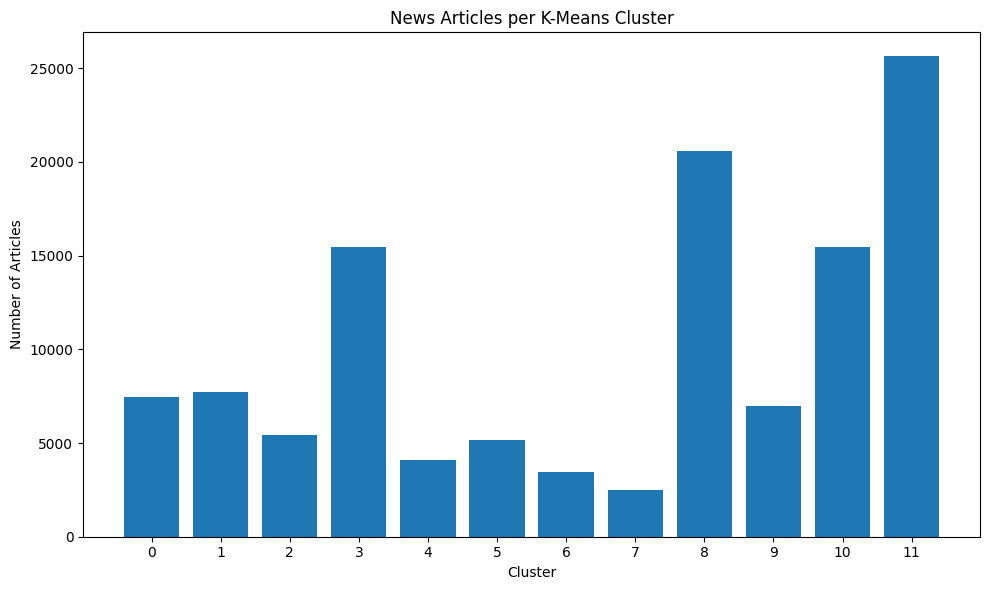

In [93]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate cluster sizes
cluster_sizes = np.bincount(final_kmeans.labels_, minlength=final_k)

# Plot
plt.figure(figsize=(10, 6))

plt.bar(
    range(final_k),
    cluster_sizes
)

plt.xlabel("Cluster")
plt.ylabel("Number of Articles")
plt.title("News Articles per K-Means Cluster")
plt.xticks(range(final_k))

plt.tight_layout()
plt.show()